First 5 records:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1                 91  
1                                 2                 65  
2                                 2                 45  
3                                 2                 36  
4                                 5                 66  

Missing values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Qu

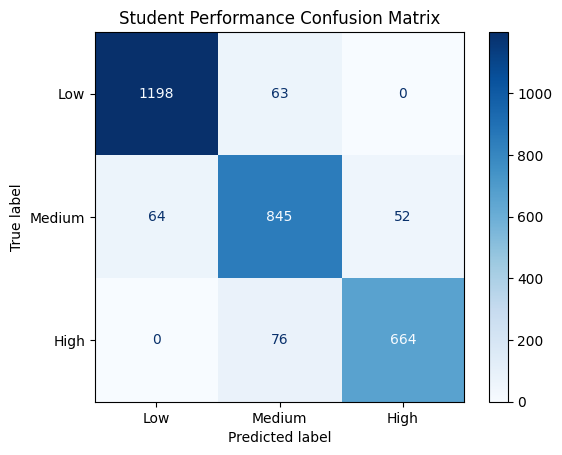

In [9]:

# KNN CLASSIFICATION FOR STUDENT PERFORMANCE

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# 1. Load dataset
df = pd.read_csv("/content/Student_Performance - Student_Performance.csv")

print("First 5 records:")
print(df.head())

# 2. Check class distribution and missing values
print("\nMissing values:")
print(df.isnull().sum())

df.drop_duplicates(inplace=True)

# Fill missing values
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# 3. Convert Performance Index into classes
# Numerical Performance Index into categories: Low, Medium, and High because KNeighborsClassifier predicts categories
df["Performance"] = pd.cut(
    df["Performance Index"],
    bins=[-float("inf"), 50, 70, float("inf")],
    # Low: score ≤ 50
    # Medium: score > 50 and ≤ 70
    # High: score > 70
    labels=["Low", "Medium", "High"]
)

print("\nClass Distribution:")
print(df["Performance"].value_counts())

# 4. Convert categorical column into numeric
# X input would be numeric as we want to find distance and Y is category as we want to predict that
df["Extracurricular Activities"] = df[
    "Extracurricular Activities"
].map({"Yes": 1, "No": 0})

# 5. Select features and target
X = df[
    [
        "Hours Studied",
        "Previous Scores",
        "Extracurricular Activities",
        "Sleep Hours",
        "Sample Question Papers Practiced"
    ]
]

y = df["Performance"]

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 7. Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 8. Test different K values
k_values = [3, 5, 7]
results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    results.append({
        "K": k,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ), 4),
        "Recall": round(recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ), 4)
    })

print("\nK Value Comparison:")
print(pd.DataFrame(results).to_string(index=False))

# 9. Select best K based on test accuracy
accuracies = [row["Accuracy"] for row in results]

best_index = accuracies.index(max(accuracies))
best_k = k_values[best_index]

print("\nSelected K:", best_k)

# Train final model
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

# 10. Predict student performance
y_pred = final_model.predict(X_test_scaled)

print("\nActual vs Predicted:")
print(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).head())

# 11. Evaluate model
print("\nFinal Model Evaluation:")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(
    y_test, y_pred, average="macro", zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, y_pred, average="macro", zero_division=0
), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 12. Confusion matrix
labels = ["Low", "Medium", "High"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues")
plt.title("Student Performance Confusion Matrix")
plt.show()
